#### 1. Import Libaries

In [53]:
!pip install sastrawi

In [54]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# Import torch/transformers FIRST
import torch
from transformers import pipeline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

#### 2. Data loading

In [55]:
df = pd.read_csv("PSN_articles.csv")

print(df.shape)

df

(193, 7)


,title,source,published,google_link,url,text,text_for_sentiment
0,"Pemkab Ketapang Gandeng PSN Hadirkan Internet ke Desa Blank Spot, Akses Digital Ditargetkan Maki...",Pontianak Post,2026-07-09 07:00:00+00:00,https://news.google.com/rss/articles/CBMi6wFBVV95cUxON1lDdFVMMEo5SzM2eXhXSldGUXFuel9sMThRS3Z4YTh...,https://pontianakpost.jawapos.com/ketapang/2607090020/pemkab-ketapang-gandeng-psn-hadirkan-inter...,NaN,"Pemkab Ketapang Gandeng PSN Hadirkan Internet ke Desa Blank Spot, Akses Digital Ditargetkan Maki..."
1,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink",Bisnis Tekno,2026-07-08 07:00:00+00:00,https://news.google.com/rss/articles/CBMiywFBVV95cUxNLXU3bGJOSWg1Ml9JTkhXdFNKQVlDRi1nS0pYb1MwVlJ...,https://teknologi.bisnis.com/read/20260708/101/1986612/psn-dan-telkomsat-ajukan-slot-orbit-satel...,NaN,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink"
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Satelit GEO Indonesia Belum Berakhir",Bisnis Tekno,2026-06-02 07:00:00+00:00,https://news.google.com/rss/articles/CBMizwFBVV95cUxNdEl1RFFDd2lWZGhkQlh4amI5c2k2NFJ5SzQwVXpmNzk...,https://teknologi.bisnis.com/read/20260602/101/1977890/dominasi-starlink-makin-kuat-psn-sebut-er...,NaN,"Dominasi Starlink Makin Kuat, PSN Sebut Era Satelit GEO Indonesia Belum Berakhir"
3,"🛰️ Indonesia’s Nusantara Lima begins operations, boosting digital connectivity and space ambitions",The Southeast Asia Desk,2026-05-19 07:00:00+00:00,https://news.google.com/rss/articles/CBMie0FVX3lxTFBmc3RnUld6YWhHTGlTcjB0ZXBGcHBzaHI3Z0dGbTlyWmN...,https://www.thesoutheastasiadesk.com/p/indonesias-nusantara-lima-begins,"🎯 The Main Takeaway\nIndonesia’s newest satellite, Nusantara Lima, officially began its full ope...","🎯 The Main Takeaway\nIndonesia’s newest satellite, Nusantara Lima, officially began its full ope..."
4,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima,SWA.co.id,2026-05-17 07:00:00+00:00,https://news.google.com/rss/articles/CBMilAFBVV95cUxPTG8wTGZCb0RVWV9SYmNoZHJEUk5WbG84eEdvT2ZWVW5...,https://swa.co.id/read/472659/foto-bisnis-swa-peresmian-operasional-satelit-nusantara-lima,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima\nDilarang keras mengambil konten (...,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima\nDilarang keras mengambil konten (...
...,...,...,...,...,...,...,...
188,PSN-6 satellite (SSL),Teslarati,2019-01-15 12:19:49+00:00,https://news.google.com/rss/articles/CBMitgFBVV95cUxPQ1BQSHFTQ1Mwd2N2M0MwTUF5T3JLNU5vYmhnSElpUGN...,https://www.teslarati.com/spacex-falcon-9-lunar-rideshare-launch-prime-payload-florida-arrival/p...,Elon Musk just confirmed the Tesla and SpaceX merger step everyone was waiting for\nSpaceX deliv...,Elon Musk just confirmed the Tesla and SpaceX merger step everyone was waiting for\nSpaceX deliv...
189,PSN Siap Luncurkan Satelit PSN VI Berkapasitas 15 Gbps,CNN Indonesia,2017-12-07 08:00:00+00:00,https://news.google.com/rss/articles/CBMiuwFBVV95cUxNaHNVZ1ZsMUZzdFdGM0dnSnp0My0wNmlUdG00ZThJRzF...,https://www.cnnindonesia.com/teknologi/20171205203353-213-260361/psn-siap-luncurkan-satelit-psn-...,"Jakarta, CNN Indonesia -- PT Pasifik Satelit Nusantara (PSN) melakukan penandatanganan kontrak p...","Jakarta, CNN Indonesia -- PT Pasifik Satelit Nusantara (PSN) melakukan penandatanganan kontrak p..."
190,"Bangun Satelit PALAPA-N1, PT Pasifik Satelit Nusantara Jalin Kerja Sama Strategis",JPNN.com,2017-05-22 07:00:00+00:00,https://news.google.com/rss/articles/CBMiqgFBVV95cUxQNTdqZFIzZkJ0TmdtZFNCRW5Pakp2U1QxYWJ0UWtjWEV...,https://www.jpnn.com/news/bangun-satelit-palapa-n1-pt-pasifik-satelit-nusantara-jalin-kerja-sama...,"Bangun Satelit PALAPA-N1, PT Pasifik Satelit Nusantara Jalin Kerja Sama Strategis\njpnn.com - PT...","Bangun Satelit PALAPA-N1, PT Pasifik Satelit Nusantara Jalin Kerja Sama Strategis\njpnn.com - PT..."
191,Indosat-PSN beli satelit Palapa-N1 dari perusahaan China,ANTARA News,2017-05-17 07:00:00+00:00,https://news.google.com/rs

#### 3. EDA

##### Dataframe info

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   title               193 non-null    object
 1   source              193 non-null    object
 2   published           193 non-null    object
 3   google_link         193 non-null    object
 4   url                 193 non-null    object
 5   text                160 non-null    object
 6   text_for_sentiment  193 non-null    object
dtypes: object(7)
memory usage: 10.7+ KB


In [57]:
df.isnull().sum()

title                  0
source                 0
published              0
google_link            0
url                    0
text                  33
text_for_sentiment     0
dtype: int64

##### Checking Duplicates

In [58]:
df["title"].str.lower().str.strip().duplicated().sum()

0

In [59]:
df["url"].duplicated().sum()

0

##### Dates of article published

In [60]:
# converting time to datetime
df["published"] = pd.to_datetime(df["published"], utc=True)
df["year"] = df["published"].dt.year

In [61]:
# showing articles from oldest to newest
print(df["published"].min())
print(df["published"].max())

2017-05-17 07:00:00+00:00
2026-07-09 07:00:00+00:00


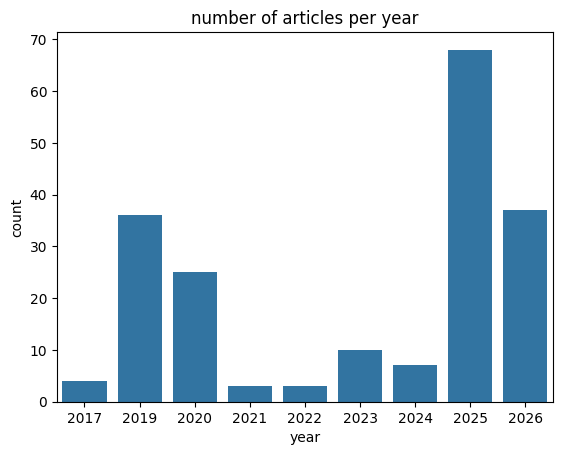

In [62]:
# number of articles per year
sns.countplot(data=df, x="year")
plt.title("number of articles per year")
plt.show()

##### Articles sources that dominates the most

In [63]:
print(df["source"].nunique())
df["source"].value_counts().head(10)

75


source
detikInet        34
Bisnis Tekno     13
Kompas.id        10
Suara.com        10
Tempo.co          9
Kumparan.com      9
ANTARA News       7
Kompas.com        6
InvestorTrust     5
kontan.co.id      4
Name: count, dtype: int64

##### The length of text 

count     193.0
mean      363.0
std       310.0
min         7.0
25%       124.0
50%       328.0
75%       511.0
max      1688.0
Name: word_count, dtype: float64


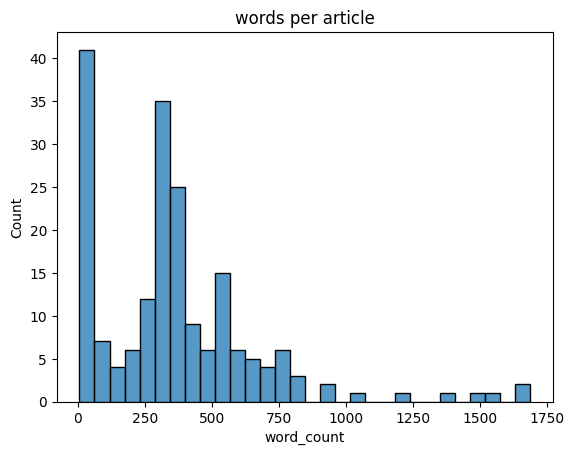

In [64]:
df["word_count"] = df["text_for_sentiment"].str.split().str.len()

print(df["word_count"].describe().round(0))

sns.histplot(data=df, x="word_count", bins=30)
plt.title("words per article")
plt.show()

here we can explore on how many articles that have only a title and how many that are fewer than 30 words from data scraping

In [65]:
print("title only:", df["text"].isnull().sum())

title only: 33


In [66]:
print("fewer than 30 words:", (df["word_count"] < 30).sum())

fewer than 30 words: 33


##### Finding what language the data dominates

In [67]:
first_part = df["text_for_sentiment"].str.lower().str[:500]
df["indo_words"] = first_part.str.count(r"\b(?:yang|dan|untuk|dengan|dari|pada|ini|satelit)\b")

df["language"] = np.where(df["indo_words"] >=3, "Indonesian", "English/other")

df["language"].value_counts()

language
Indonesian       141
English/other     52
Name: count, dtype: int64

##### Validating if the articles are about psn

In [68]:
keywords = "PSN|Pasifik Satelit|Pacific Satelite|Nusantara"
df["mentions_psn"] = df["text_for_sentiment"].str.contains(keywords, case=False, regex=True)

print(df["mentions_psn"].value_counts())

df[~df["mentions_psn"]][["title", "source"]]

mentions_psn
True     190
False      3
Name: count, dtype: int64


,title,source
37,Adi Rahman Adiwoso Raih Penghargaan Aerospace Technology Pioneer di BIG 40 Award,Bisnis Tekno
127,"Adi Rahman Adiwoso, Teknologiwan Indonesia yang Membuat Kita Tetap Bisa Menelepon di Area Tanpa ...",nukilan.id
188,PSN-6 satellite (SSL),Teslarati


#### 4. Data cleaning

the text from data scrapping is almost a mess with line breaks, extra spaces, duplicate and empty texts. this aims to clean the said text

In [69]:
# this cell will be for text cleaning

df["clean_text"] = df["text_for_sentiment"]

# replace line breaks with space
df["clean_text"] = df["clean_text"].str.replace("\n", " ", regex=True)

# removing domains
df["clean_text"] = df["clean_text"].str.replace("Dilarang keras mengambil konten.*?(?:situs web ini [.]|ANTARA[.])", "", regex=True)

# removing links
df["clean_text"] = df["clean_text"].str.replace("https?://[^ ]+", "", regex=True)

# change spaces into one space
df["clean_text"] = df["clean_text"].str.replace(" +", " ", regex=True)

# remove spaces at the start sentence and at the end of the sentence
df["clean_text"] = df["clean_text"].str.strip()

In [70]:
# Removing duplicate articles 
rows_before = df.shape[0]
df = df.drop_duplicates(subset="title")

# Removing articles if the content is none after cleaning
df = df[df["clean_text"].str.len() > 0]

# Reset row numbers after cleaning
df = df.reset_index(drop=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   title               193 non-null    object             
 1   source              193 non-null    object             
 2   published           193 non-null    datetime64[ns, UTC]
 3   google_link         193 non-null    object             
 4   url                 193 non-null    object             
 5   text                160 non-null    object             
 6   text_for_sentiment  193 non-null    object             
 7   year                193 non-null    int32              
 8   word_count          193 non-null    int64              
 9   indo_words          193 non-null    int64              
 10  language            193 non-null    object             
 11  mentions_psn        193 non-null    bool               
 12  clean_text          193 non-null    

checking the result of text before and after cleaning

In [71]:
print("Before:", round(df["text_for_sentiment"].str.len().mean()), "characters")
print("After:", round(df["clean_text"].str.len().mean()), "characters")

Before: 2675 characters
After: 2643 characters


#### 5. Adding lables using pre-trained sentiment model

##### Loading the model



the data i scraped doesn't come with sentiment, so i do a workaround by using a pre-trained sentiment model.

here i will be using ```lxyuan_distilbert``` and ```xlm_roberta``` to compare and to decide which one is better for labeling the PSN articles. I compare their label counts, agreement, and confidence scores

In [72]:
# model 1 Distilbert
lxyuan_distilbert_classifier = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student"
)

Device set to use cpu


In [73]:
# model 2: XLM-Roberta
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")
model = AutoModelForSequenceClassification.from_pretrained("cardiffnlp/twitter-xlm-roberta-base-sentiment")

xlm_roberta_base = pipeline(
    "sentiment-analysis", 
    model=model, 
    tokenizer=tokenizer)

Device set to use cpu


In [74]:
texts = df["clean_text"].tolist()

#loading two models
distilbert_result = lxyuan_distilbert_classifier(texts, truncation=True, max_length=512, batch_size=8)
xlm_result = xlm_roberta_base(texts, truncation=True, max_length=512)

##### Label Comparison on each models

In [75]:
# put both results into a seperate table
compare_df = pd.DataFrame({
    "text": texts,
    "label_distilbert": pd.DataFrame(distilbert_result)["label"].str.lower(),
    "score_distilbert": pd.DataFrame(distilbert_result)["score"],
    "label_xlm": pd.DataFrame(xlm_result)["label"].str.lower(),
    "score_xlm": pd.DataFrame(xlm_result)["score"]
})

compare_df.head(10)


,text,label_distilbert,score_distilbert,label_xlm,score_xlm
0,"Pemkab Ketapang Gandeng PSN Hadirkan Internet ke Desa Blank Spot, Akses Digital Ditargetkan Maki...",positive,0.546819,positive,0.579546
1,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink",positive,0.545614,neutral,0.703243
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Satelit GEO Indonesia Belum Berakhir",positive,0.660443,positive,0.473927
3,"🎯 The Main Takeaway Indonesia’s newest satellite, Nusantara Lima, officially began its full oper...",positive,0.467914,neutral,0.460888
4,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima Dilarang keras mengambil konten (t...,positive,0.551659,neutral,0.721646
5,Can't find what you're looking for? View all search results Nusantara 5 (N5) satellite is Asia's...,positive,0.635248,neutral,0.461794
6,The Nusantara Lima Satellite has officially commenced operations and is anticipated to significa...,positive,0.821756,neutral,0.422207
7,Satelit Nusantara Lima Menjadi Satelit Terbesar di Asia yang Berspesifikasi Very High Throughput...,positive,0.555935,neutral,0.657592
8,"PSN Gelontorkan Investasi Lebih Rp 23 Triliun, Siapkan Satelit Baru hingga 2028 Poin Penting | ●...",positive,0.729301,neutral,0.531458
9,"Tantang Starlink, PSN Andalkan Satelit Lokal dan Antena Buatan Dalam Negeri Poin Penting | ● | P...",positive,0.598618,neutral,0.558645


##### Label distribution
here, i want to see the difference of sentiment distribution by comparing each label on each model

In [76]:
# showing the comparison dataframe
pd.DataFrame({
    "distilbert": compare_df["label_distilbert"].value_counts(),
    "xlm": compare_df["label_xlm"].value_counts()
})

,distilbert,xlm
negative,32,4
neutral,2,177
positive,159,12


based on this result, Distilbert has 159 positive, but xlm has 177 neutral. the two models labels the data very differently.

##### Comparing confidence score
here i will be comparing both confidence scores, the higher the score the better the model at labeling

In [77]:
print("DistilBERT avg score:", compare_df["score_distilbert"].mean())
print("XLM avg score:", compare_df["score_xlm"].mean())

DistilBERT avg score: 0.6558425233462931
XLM avg score: 0.5616082382325681


The average confidence is close. DistilBERT is 0.66 and XLM is 0.56. Both scores are fairly low, which means neither model is very sure about its labels on these news articles. Confidence alone cannot justify which model is better.

##### Comparing pre trained model evaluation metrics by manually labeled data

since confidence score alone cannot justify which pre trained model is the best for this study case. Manual label will be implemented about 80 articles based on titles, then compares them from evaluation metrics.

In [78]:
labels = pd.read_csv("labeled_sample.csv", index_col=0)
labeled = compare_df.join(labels["true_label"], how="inner")
print(labeled.shape)   # should print (80, 6)

(80, 6)


In [79]:
print("DistilBERT")
print(classification_report(labeled["true_label"], labeled["label_distilbert"]))

print("XLM")
print(classification_report(labeled["true_label"], labeled["label_xlm"]))

DistilBERT
              precision    recall  f1-score   support

    negative       0.64      0.88      0.74         8
     neutral       0.00      0.00      0.00        42
    positive       0.41      0.93      0.57        30

    accuracy                           0.44        80
   macro avg       0.35      0.60      0.44        80
weighted avg       0.22      0.44      0.29        80

XLM
              precision    recall  f1-score   support

    negative       0.67      0.25      0.36         8
     neutral       0.55      0.93      0.69        42
    positive       0.50      0.10      0.17        30

    accuracy                           0.55        80
   macro avg       0.57      0.43      0.41        80
weighted avg       0.54      0.55      0.46        80



Cutting to the important part of evaluation metrics :
- accuracy
- f1
so i can compare them based on the two metrics

In [80]:
compare_metrics_model = pd.DataFrame({
    "model": ["distilbert", "xlm"],
    "accuracy": [
        accuracy_score(labeled["true_label"], labeled["label_distilbert"]),
        accuracy_score(labeled["true_label"], labeled["label_xlm"])
    ],
    "f1": [
        f1_score(labeled["true_label"], labeled["label_distilbert"], average="macro"),
        f1_score(labeled["true_label"], labeled["label_xlm"], average="macro")
    ]
})

compare_metrics_model.round(3)

,model,accuracy,f1
0,distilbert,0.438,0.436
1,xlm,0.550,0.407


based on the results of evaluation metrics we can gather the results :

| | Macro F1 | Accuracy | Negative found | Positive found | Neutral found |
|---|---|---|---|---|---|
| DistilBERT | 0.44 | 0.44 | 7 of 8 | 28 of 30 | 0 of 42 |
| XLM | 0.41 | 0.55 | 2 of 8 | 3 of 30 | 39 of 42 |

we can analyze that 
- DistilBERT over-predicts positive and almost never says neutral.
- XLM over-predicts neutral and misses most positive and negative articles.
- XLM's higher accuracy is misleading: 52% of the sample is neutral, so always answering "neutral" would score almost the same.

hence, i decided to use **DistilBERT** for the rest of the project. the main reason is because to measure sentiment, DistilBERT detects positive and negative articles much efficient. meanwhwile XLM would label almost every article neutral, leaving little sentiment to analyze

##### Adding lables with distilbert

here i will be reusing its results from distilbert. the model will give labels and confidence score.

In [81]:
# Distilbert results
results_df = pd.DataFrame(distilbert_result)

# Adding the lables and confidence scores to main table
df["sentiment_pretrained"] = results_df["label"]
df["confidence"] = results_df["score"]

df[["title", "sentiment_pretrained", "confidence"]].head(10)

,title,sentiment_pretrained,confidence
0,"Pemkab Ketapang Gandeng PSN Hadirkan Internet ke Desa Blank Spot, Akses Digital Ditargetkan Maki...",positive,0.546819
1,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink",positive,0.545614
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Satelit GEO Indonesia Belum Berakhir",positive,0.660443
3,"🛰️ Indonesia’s Nusantara Lima begins operations, boosting digital connectivity and space ambitions",positive,0.467914
4,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima,positive,0.551659
5,PSN’s Nusantara 5 satellite officially starts operations,positive,0.635248
6,Nusantara Lima Satellite Expands Indonesia’s AI-Ready Regional Internet Connectivity,positive,0.821756
7,Satelit Nusantara Lima Menjadi Satelit Terbesar di Asia yang Berspesifikasi Very High Throughput...,positive,0.555935
8,"PSN Gelontorkan Investasi Lebih Rp 23 Triliun, Siapkan Satelit Baru hingga 2028",positive,0.729301
9,"Tantang Starlink, PSN Andalkan Satelit Lokal dan Antena Buatan Dalam Negeri",positive,0.598618


##### Checking labels

here i will doing EDA for data that has been labeled from distilbert, where I looked at 15 random articles and at the articles where the model is unsure (confidence below 0.6).

In [82]:
# checking the labels of 15 random articles
pd.set_option("display.max_colwidth", 100)
df[["title", "sentiment_pretrained", "confidence"]].sample(15, random_state=42)

,title,sentiment_pretrained,confidence
45,"Setelah Mengorbit, Apa Manfaat Satelit Nusantara Lima bagi Indonesia?",positive,0.671746
137,"Satelit Nusantara Dua Gagal Mengorbit, Layanan Penyiaran Tetap Aman",negative,0.515844
76,Bos PSN Optimistis Satelit Nusantara Lima Meluncur ke Angkasa Hari Ini,negative,0.568133
144,Satelit Nusantara Dua Gagal Mengorbit Karena Masalah Teknis,negative,0.756740
113,"Perkuat Ekosistem Satelit Nasional, PSN dan BRIN Umumkan Kemitraan Strategis",positive,0.857547
152,"Akses Internet Terbatas, PSN Hadirkan Ubiqu Sinyalku untuk Daerah Pelosok",positive,0.649903
15,"Indonesia luncurkan Satelit Nusantara Lima, percepat pemerataan internet",positive,0.861967
18,Berita Kini - Menkomdigi Meutya Hafid: Satelit Nusantara Lima Bukti Nyata Kedaulatan Digital Ind...,positive,0.594149
16,"Satelit Nusantara Lima Dilirik Filipina dan Malaysia, PSN Klaim Terbesar di Asia",positive,0.824397
9,"Tantang Starlink, PSN Andalkan Satelit Lokal dan Antena Buatan Dalam Negeri",positive,0.598618


In [83]:
# showing labels below 0.6 confidence score
df[df["confidence"] < 0.6][["title", "sentiment_pretrained", "confidence"]]

,title,sentiment_pretrained,confidence
0,"Pemkab Ketapang Gandeng PSN Hadirkan Internet ke Desa Blank Spot, Akses Digital Ditargetkan Maki...",positive,0.546819
1,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink",positive,0.545614
3,"🛰️ Indonesia’s Nusantara Lima begins operations, boosting digital connectivity and space ambitions",positive,0.467914
4,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima,positive,0.551659
7,Satelit Nusantara Lima Menjadi Satelit Terbesar di Asia yang Berspesifikasi Very High Throughput...,positive,0.555935
...,...,...,...
181,"Siap-Siap, Satelit Nusantara Satu ""Mengangkasa"" Besok",positive,0.467954
187,Satelit Kapasitas Jumbo Nusantara Satu Mengorbit pada Februari,positive,0.488678
188,PSN-6 satellite (SSL),negative,0.466345
189,PSN Siap Luncurkan Satelit PSN VI Berkapasitas 15 Gbps,positive,0.592772




From the random 15 sample, i can conclude that 
- The model gave 12 positive, 3 negative and **0 neutral** labels.
- the two articles about Nusantara Dua failing to reach orbit are negative, and articles about successful launches (for example "Nusantara Tiga Sukses Sampai di Orbit") are positive.
- Some labels misses their predictions. "Bos PSN Optimistis ... Meluncur Hari Ini" is negative (0.57), although the title sounds positive. "Apa Manfaat Satelit Nusantara Lima bagi Indonesia?" and the partnership articles (PSN and BRIN, Kominfo and PSN) are positive, but they are informational, so it would be neutral.

From articles that has the confidence score below 0.6, i can conclude that 
- In the rows shown, almost all are positive, and many are factual announcements. for example, an orbit slot application, a satellite purchase, a photo caption, even a satellite name ("PSN-6 satellite (SSL)", labeled negative). These are neutral news.
- "SpaceX Sukses Luncurkan..." is clearly positive but only has 0.45 confidence score. meanwhile, the BRIN partnership, which was talking about factual articles has 0.86 is positive. This shows that the model is simply inconsistent and struggles to guess its own accuracy.


with all of the above, i can gather that  The model works well for clear good or bad events (success, failure), but it tends to label neutral, informational news as positive. So the positive count is probably too high. This matches the reference sample result in Distilbert Lablelling, where DistilBERT almost never predicted neutral.

#### 6. Modelling: Logistic Regression and Naive Bayes

##### Splitting into train and test set 

In [84]:
X = df["clean_text"]
y = df["sentiment_pretrained"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Train size: 154
Test size: 39


##### Turn text into numbers (TF-IDF)

In [85]:
vectorizer = TfidfVectorizer(max_features=5000, min_df=2)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

print(X_train_tfidf.shape)

(154, 3057)


##### Logistic regression model definition

In [86]:
logreg_model = LogisticRegression(max_iter=1000)

logreg_model.fit(X_train_tfidf, y_train)

logreg_pred = logreg_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, logreg_pred))
print(classification_report(y_test, logreg_pred))

Accuracy: 0.9230769230769231
              precision    recall  f1-score   support

    negative       1.00      0.57      0.73         7
    positive       0.91      1.00      0.96        32

    accuracy                           0.92        39
   macro avg       0.96      0.79      0.84        39
weighted avg       0.93      0.92      0.91        39



##### Naive bayes model definition

In [87]:
Naive_model = MultinomialNB()

Naive_model.fit(X_train_tfidf, y_train)

Naive_pred = Naive_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, Naive_pred))
print(classification_report(y_test, Naive_pred))


Accuracy: 0.8205128205128205
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         7
    positive       0.82      1.00      0.90        32

    accuracy                           0.82        39
   macro avg       0.41      0.50      0.45        39
weighted avg       0.67      0.82      0.74        39



c:\conda3\envs\h8_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\conda3\envs\h8_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\conda3\envs\h8_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


##### Model Score Comparison

In [88]:
model_compare = pd.DataFrame({
    "model": ["LogisticRegression", "Naive Bayes"],
    "accuracy": [accuracy_score(y_test, logreg_pred), accuracy_score(y_test, Naive_pred)],
    "f1": [f1_score(y_test, logreg_pred, average="macro"), f1_score(y_test, Naive_pred, average="macro")]
})

model_compare.round(3)

,model,accuracy,f1
0,LogisticRegression,0.923,0.841
1,Naive Bayes,0.821,0.451


Based on these metrics, Logistic Regression performs better than Naive Bayes on both accuracy (0.923 vs 0.821) and F1 score (0.841 vs 0.451). Naive Bayes low F1 suggests it does badly on some sentiments, probably the smaller classes (neutral and negative). Logistic Regression does better across the classes.

However, these scores should be read more carefully. Both models learn from labels made by DistilBERT, which labeled most articles positive and probably over-counts positive. So a high score means the model copies DistilBERT's labels well, not that it understands real sentiment.

Text(0.5, 1.0, 'Naive Bayes')

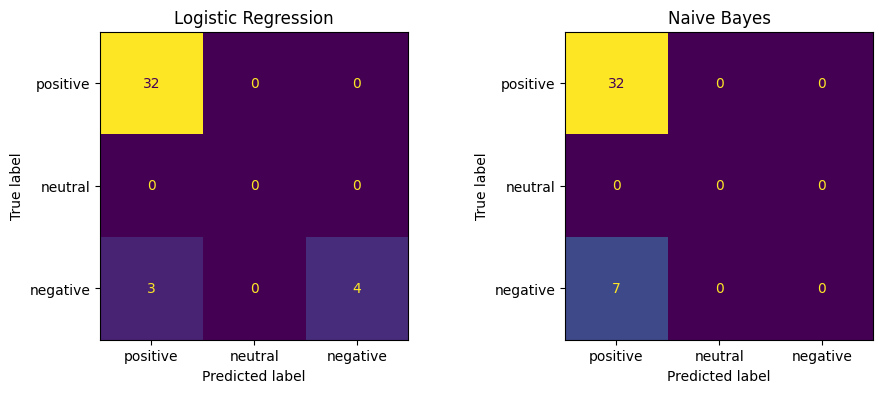

In [89]:
order = ["positive", "neutral", "negative"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(y_test, logreg_pred, labels=order, ax=axes[0], colorbar=False)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(y_test, Naive_pred, labels=order, ax=axes[1], colorbar=False)
axes[1].set_title("Naive Bayes")


based on evaluation metrics on logistic regression and naive bayes model, The test set has 39 articles: 32 positive, 7 negative and 0 neutral. Naive Bayes predicts "positive" for every article, so it finds none of the 7 negative articles. This explains its accuracy of 0.821 (32 of 39) and its low F1 score. Logistic Regression finds 4 of the 7 negative articles, but still labels 3 of them as positive. So both models lean strongly toward positive.

There is no neutral article in the test set, because DistilBERT labeled only 2 articles neutral in the whole dataset. This means those two models cannot learn a neutral class. this is a clear limitation inherited from the pre-trained labels.

the two metrics defines on what the best approach for this project. Logistic Regression is the better model. it finds some negative articles, while Naive Bayes predicts positive for everything.

##### Text preprocessing

Here i will do text stop words removal so that the top words show real topics and not filler words like *the*, *from*, *yang* and *dengan*.The previous model score comparing of Logistic Regression and Naive Bayes did not use stopword removal, so it works as a baseline. Only the tuned final model uses it.

In [101]:
indonesian_stopwords = StopWordRemoverFactory().get_stop_words()
all_stopwords = list(ENGLISH_STOP_WORDS) + list(indonesian_stopwords)


do a quick check on how many stopwords are on the list 

In [102]:
print(len(all_stopwords))
print([w for w in ["gagal", "satelit", "orbit", "kapan", "batal"] if w in all_stopwords])

444
[]


this shows that the words i've checked, which is ```"gagal", "satelit", "orbit", "kapan", "batal"``` doesnt get removed from stopword removal.

##### Hyperparameter tuning

Logistic Regression will be used for the rest of the project, because it performs better than Naive Bayes. it finds some negative articles, while Naive Bayes predicts positive for every article. Hyperparameter tuning will be added to try to improve the model further.

In [92]:
logreg_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, stop_words=all_stopwords)),
    ("clf", LogisticRegression(max_iter=1000))
])

logreg_param = {
    "tfidf__max_features": [2000, 5000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [0.1, 1, 10]
}

logreg_grid = GridSearchCV(logreg_pipe, logreg_param, cv=5, scoring="f1_macro")
logreg_grid.fit(X_train, y_train)

print("Best Param:", logreg_grid.best_params_)
print("Best f1 cross validation:", round(logreg_grid.best_score_, 3))

c:\conda3\envs\h8_env\lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(


Best Param: {'clf__C': 10, 'tfidf__max_features': 2000, 'tfidf__ngram_range': (1, 1)}
Best f1 cross validation: 0.612


GridSearchCV tried 12 combinations. The best parameters were C = 10, max_features = 2000 and ngram_range = (1, 1), with a cross-validation f1 score of 0.612. This score is lower than the logreg test score (0.841), but they are not comparable. Then the model will be saved for sentiment analysis

In [93]:
final_model = logreg_grid.best_estimator_
print(final_model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=2000, min_df=2,
                                 stop_words=['seems', 'still', 'been',
                                             'amongst', 'beside', 'ours', 'had',
                                             'rather', 'about', 'four', 'three',
                                             'as', 'where', 'twenty',
                                             'throughout', 'moreover',
                                             'himself', 'none', 'against',
                                             'your', 'anyway', 'are', 'top',
                                             'get', 'together', 'six', 'her',
                                             'becomes', 'ltd', 'front', ...])),
                ('clf', LogisticRegression(C=10, max_iter=1000))])


#### 7. Sentiment analysis

Here, i want to explore 4 things based on sentiment labels
- How is the topic portrayed overall ? 
- How does it change overtime ? Does sentiment shift around specific events ?
- Do sources differ ? Does one publisher write more negatively than the others ?
- Which words drive the sentiment ?
 

since the rest of the project will be using logistic regression which is the final model, where as Distilbert only used as labeling, chapter 7 will be using the final model for sentiment analysis.

In [94]:
# this cell will be used for cleaning the dataframe after the modelling process from chapter 6 and 5

# Labels from logistic regression
df["sentiment"] = final_model.predict(df["clean_text"])

# Dropping columns to have a clean label 
df = df.drop(columns=["sentiment_pretrained", "confidence", "sentiment_model"], errors="ignore")
df.head(10)


,title,source,published,google_link,url,text,text_for_sentiment,year,word_count,indo_words,language,mentions_psn,clean_text,sentiment
0,"Pemkab Ketapang Gandeng PSN Hadirkan Internet ke Desa Blank Spot, Akses Digital Ditargetkan Maki...",Pontianak Post,2026-07-09 07:00:00+00:00,https://news.google.com/rss/articles/CBMi6wFBVV95cUxON1lDdFVMMEo5SzM2eXhXSldGUXFuel9sMThRS3Z4YTh...,https://pontianakpost.jawapos.com/ketapang/2607090020/pemkab-ketapang-gandeng-psn-hadirkan-inter...,NaN,"Pemkab Ketapang Gandeng PSN Hadirkan Internet ke Desa Blank Spot, Akses Digital Ditargetkan Maki...",2026,15,0,English/other,True,"Pemkab Ketapang Gandeng PSN Hadirkan Internet ke Desa Blank Spot, Akses Digital Ditargetkan Maki...",positive
1,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink",Bisnis Tekno,2026-07-08 07:00:00+00:00,https://news.google.com/rss/articles/CBMiywFBVV95cUxNLXU3bGJOSWg1Ml9JTkhXdFNKQVlDRi1nS0pYb1MwVlJ...,https://teknologi.bisnis.com/read/20260708/101/1986612/psn-dan-telkomsat-ajukan-slot-orbit-satel...,NaN,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink",2026,13,2,English/other,True,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink",positive
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Satelit GEO Indonesia Belum Berakhir",Bisnis Tekno,2026-06-02 07:00:00+00:00,https://news.google.com/rss/articles/CBMizwFBVV95cUxNdEl1RFFDd2lWZGhkQlh4amI5c2k2NFJ5SzQwVXpmNzk...,https://teknologi.bisnis.com/read/20260602/101/1977890/dominasi-starlink-makin-kuat-psn-sebut-er...,NaN,"Dominasi Starlink Makin Kuat, PSN Sebut Era Satelit GEO Indonesia Belum Berakhir",2026,12,1,English/other,True,"Dominasi Starlink Makin Kuat, PSN Sebut Era Satelit GEO Indonesia Belum Berakhir",positive
3,"🛰️ Indonesia’s Nusantara Lima begins operations, boosting digital connectivity and space ambitions",The Southeast Asia Desk,2026-05-19 07:00:00+00:00,https://news.google.com/rss/articles/CBMie0FVX3lxTFBmc3RnUld6YWhHTGlTcjB0ZXBGcHBzaHI3Z0dGbTlyWmN...,https://www.thesoutheastasiadesk.com/p/indonesias-nusantara-lima-begins,"🎯 The Main Takeaway\nIndonesia’s newest satellite, Nusantara Lima, officially began its full ope...","🎯 The Main Takeaway\nIndonesia’s newest satellite, Nusantara Lima, officially began its full ope...",2026,1500,1,English/other,True,"🎯 The Main Takeaway Indonesia’s newest satellite, Nusantara Lima, officially began its full oper...",positive
4,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima,SWA.co.id,2026-05-17 07:00:00+00:00,https://news.google.com/rss/articles/CBMilAFBVV95cUxPTG8wTGZCb0RVWV9SYmNoZHJEUk5WbG84eEdvT2ZWVW5...,https://swa.co.id/read/472659/foto-bisnis-swa-peresmian-operasional-satelit-nusantara-lima,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima\nDilarang keras mengambil konten (...,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima\nDilarang keras mengambil konten (...,2026,49,9,Indonesian,True,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima Dilarang keras mengambil konten (t...,positive
5,PSN’s Nusantara 5 satellite officially starts operations,The Jakarta Post,2026-05-17 07:00:00+00:00,https://news.google.com/rss/articles/CBMiqgFBVV95cUxOR01DUXhQNnNQUk9MR21BYzZLM0dmbm8ybE9vRlZmQUh...,https://www.thejakartapost.com/business/2026/05/17/psns-nusantara-5-satellite-officially-starts-...,Can't find what you're looking for?\nView all search results\nNusantara 5 (N5) satellite is Asia...,Can't find what you're looking for?\nView all search results\nNusantara 5 (N5) satellite is Asia...,2026,699,0,English/other,True,Can't find what you're looking for? View all search results Nusantara 5 (N5) satellite is Asia's...,positive
6,Nusantara Lima Satellite Expands Indonesia’s AI-Ready Regional Internet Connectivity,Telecom Review Asia,2026-05-14 07:00:00+00:00,https://news.google.com/rss/articles/CBMi2gFBVV95cUxNUmdvVEVIUk5wRXp6RXRSSjN0eC1JelBfeUt6LWd5alk...,https://www.telecomreviewasia.com/news/service-ne

##### How is the topic portrayed overall ? 

Counting positive, neutral and negative articles

In [95]:
counts = df["sentiment"].value_counts()
pd.DataFrame({"articles": counts})

,articles
sentiment,
positive,161
negative,30
neutral,2


from the result, we can gather that
- Positive articles are the clear majority: for every negative article there are about 5 positive ones.
- Almost no article is neutral. News is usually factual, so this is unusual and suggests the model rarely predicts neutral.

Coverage of PSN leans more towards positive, and negative articles are a small minority. The neutral count is too low to trust.

##### How does it change over time ? 

In [96]:
order = ["positive", "neutral", "negative"]
year_counts = pd.crosstab(df["year"], df["sentiment"]).reindex(columns=order, fill_value=0)

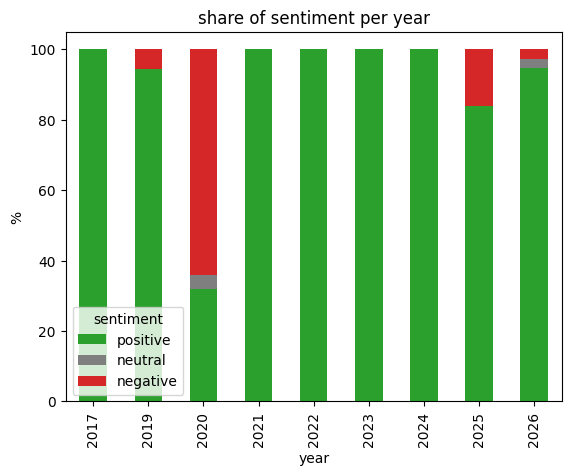

In [97]:
year_percent = year_counts.div(year_counts.sum(axis=1), axis=0) * 100

year_percent.plot(kind="bar", stacked=True, color=["tab:green", "tab:gray", "tab:red"])
plt.title("share of sentiment per year")
plt.ylabel("%")
plt.show()

In [98]:
neg = df[df["sentiment"] == "negative"].sort_values("published").copy()
neg["date"] = neg["published"].dt.date

neg[["date", "source", "title"]]

,date,source,title
188,2019-01-15,Teslarati,PSN-6 satellite (SSL)
165,2019-02-23,Tempo.co,"Satelit Nusantara Satu Sudah Mengangkasa, Kapan Mulai Berfungsi?"
149,2020-04-09,Kumparan.com,Satelit Nusantara Dua Milik Indosat dan PSN Gagal Capai Orbit - kumparan.com
148,2020-04-09,indotelko.com,Ini yang terjadi dengan Satelit Nusantara Dua
146,2020-04-09,detikInet,Anomali Roket Jadi Sebab Kegagalan Satelit Nusantara Dua
144,2020-04-09,detikInet,Satelit Nusantara Dua Gagal Mengorbit Karena Masalah Teknis
143,2020-04-10,Kompas.com,"Kronologi Satelit ""Nusantara Dua"" Gagal Mengorbit Kemudian Hancur"
141,2020-04-10,Kumparan.com,Roket Long March 3B China: Biang Masalah Satelit Palapa D dan Nusantara Dua - kumparan.com
139,2020-04-10,Suara.com,"Tidak Hanya Nusantara Dua, Satelit Milik Indonesia Ini Gagal Mengorbit"
138,2020-04-10,Kompas.com,"Ada Anomali, Satelit Nusantara Dua Gagal Mengorbit"


based on the results
- negative articles are not spread evenly. at 2020 it shows about 16 negative articles in 6 days, which makes year 2020 is the most negative year (about 60 % negative). whereas 2025 has only 8 negative articles around nusantara lima launch.
- some articles are not predicted correctly, even though the title reads positive. for example some titles with " Berhasil mengangkasa " or " Having successfully launched " was clearly positive but are labeled negative. although at 2025 the share was 11 negative articles, which is 16%. so a smaller distribution.
- some years shows 100 % positive, eg. 2017, 2021, 2024. where each has only about less than 10 articles, meanwhile 2018 has none. this is because of the data imbalance from scraping


##### Do sources differ ?

In [99]:
source_counts = df["source"].value_counts()
big_sources = source_counts[source_counts >= 5].index

df_big = df[df["source"].isin(big_sources)]

source_table = pd.crosstab(df_big["source"], df_big["sentiment"]).reindex(columns=order, fill_value=0)
source_table["total"] = source_table.sum(axis=1)
source_table["% negative"] = (source_table["negative"] / source_table["total"] * 100).round(1)

source_table.sort_values("% negative", ascending=False)

sentiment,positive,neutral,negative,total,% negative
source,,,,,
Kompas.com,2,0,4,6,66.7
Kompas.id,7,0,3,10,30.0
Suara.com,7,0,3,10,30.0
Kumparan.com,7,0,2,9,22.2
detikInet,26,1,7,34,20.6
ANTARA News,6,0,1,7,14.3
Tempo.co,8,0,1,9,11.1
Bisnis Tekno,13,0,0,13,0.0
InvestorTrust,5,0,0,5,0.0


from the dataframe above i can conclude that Kompas.com has the highest percentage of negative articles at 66.7%, but that is only 4 of 6 articles. Kompas.id and Suara.com follow at 30% each. detikInet has the most negative articles which is 7, but that is only 20.6% of its 34 articles. Bisnis Tekno and InvestorTrust have none. Since each source has only 5 to 34 articles, this data does not show a clear difference between news publishers, Testing this properly would need more articles per source.

##### Which words dominates the sentiments ?

In [100]:
tfidf = final_model.named_steps["tfidf"]
clf = final_model.named_steps["clf"]
words = np.array(tfidf.get_feature_names_out())

top_words = {}
for label in ["negative", "positive"]:
    i = list(clf.classes_).index(label)
    top_words[label] = words[np.argsort(clf.coef_[i])[-10:][::-1]]

pd.DataFrame(top_words)

,negative,positive
0,palapa,psn
1,mengangkasa,teknologi
2,launch,n5
3,satukan,menggunakan
4,59,asia
5,kapan,terbesar
6,xichang,kapasitas
7,mission,satu
8,scrub,adi
9,tesla,satria


Based on the top words, i can conclude that the words are mostly event names.
company names and common words, not emotion words. 

The filler words like *the*, *from* and *dengan* are gone after the stopword removal. 

Negative words like *palapa*, *mengangkasa* and *kapan* come from articles about launch problems and timing, while *launch*, *mission*, *scrub* and *tesla* most likely come from English articles about the SpaceX launch delays (*scrub* probably comes from the September 2025 delay articles). 

*xichang* is probably a launch site named in the 2020 failure articles. 

Positive words like *teknologi*, *kapasitas*, *terbesar* and *asia* come from descriptive news about capacity and technology, and *n5*, *satria* and *adi* are from PSN names (Nusantara Lima, the SATRIA satellite and the founder from the award articles). 

this can justify that LogisticRegression mostly learned which events and writing patterns go with each label, not which words carry emotion. With only 193 articles, these words are hints about the topics behind each sentiment, not proof.

